In [34]:
import pandas as pd
import matplotlib.pyplot as plt

In [24]:
df=pd.read_csv(r"C:\Users\nidap\Desktop\main project\ECOMMERCE ANALYSIS USING PYTHON +POWERBI\ecommerce_sales_analytics.csv")
df.head()

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,1/1/2022,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,1/2/2022,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,1/3/2022,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,1/4/2022,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,1/5/2022,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


In [25]:
df.shape

(5000, 12)

In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5000 non-null   int64  
 1   order_date        5000 non-null   object 
 2   customer_id       5000 non-null   int64  
 3   product_category  5000 non-null   object 
 4   region            5000 non-null   object 
 5   quantity          5000 non-null   int64  
 6   unit_price        5000 non-null   float64
 7   discount          5000 non-null   float64
 8   payment_method    5000 non-null   object 
 9   delivery_days     5000 non-null   int64  
 10  customer_rating   5000 non-null   float64
 11  revenue           5000 non-null   float64
dtypes: float64(4), int64(4), object(4)
memory usage: 468.9+ KB


In [27]:
df.describe()

,order_id,customer_id,quantity,unit_price,discount,delivery_days,customer_rating,revenue
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,12500.500000,1505.701200,4.044800,308.418774,0.179984,6.118800,2.973980,1021.955148
std,1443.520003,290.836902,2.020398,169.259369,0.101404,3.153264,1.157722,825.584219
min,10001.000000,1000.000000,1.000000,15.150000,0.000000,1.000000,1.000000,11.210000
25%,11250.750000,1253.000000,2.000000,161.895000,0.090000,3.000000,2.000000,354.527500
50%,12500.500000,1510.000000,4.000000,309.890000,0.180000,6.000000,3.000000,796.650000
75%,13750.250000,1761.000000,6.000000,455.557500,0.270000,9.000000,4.000000,1515.690000
max,15000.000000,1999.000000,7.000000,599.960000,0.350000,11.000000,5.000000,4119.330000


In [28]:
df.isnull().sum()

order_id            0
order_date          0
customer_id         0
product_category    0
region              0
quantity            0
unit_price          0
discount            0
payment_method      0
delivery_days       0
customer_rating     0
revenue             0
dtype: int64

In [29]:
df.duplicated().sum()

np.int64(0)

In [30]:
df['order_date']=pd.to_datetime(df['order_date'])
df.dtypes

order_id                     int64
order_date          datetime64[ns]
customer_id                  int64
product_category            object
region                      object
quantity                     int64
unit_price                 float64
discount                   float64
payment_method              object
delivery_days                int64
customer_rating            float64
revenue                    float64
dtype: object

In [38]:
category_sales=df.groupby('product_category')['revenue'].sum()
category_sales=category_sales.sort_values(ascending=False)
category_sales

product_category
Electronics    1829899.22
Clothing       1531931.72
Home            982083.92
Beauty          765860.88
Name: revenue, dtype: float64

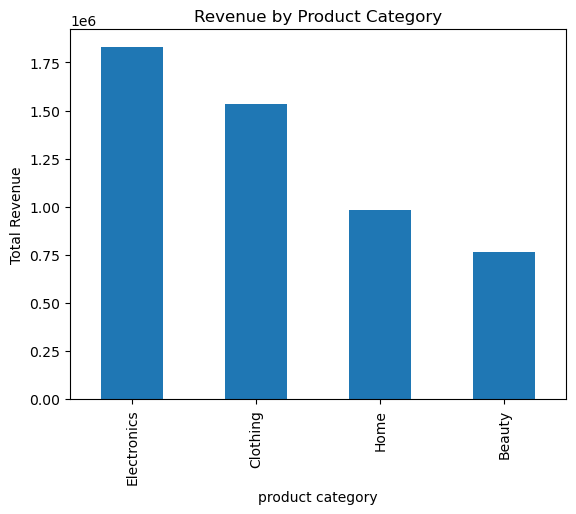

In [39]:
category_sales.plot.bar()
plt.title("Revenue by Product Category")
plt.xlabel('product category')
plt.ylabel('Total Revenue')
plt.show()

In [42]:
region_sales=df.groupby('region')['revenue'].sum()
region_sales=region_sales.sort_values(ascending=False)
region_sales

region
West     1345582.16
North    1281508.45
South    1246640.90
East     1236044.23
Name: revenue, dtype: float64

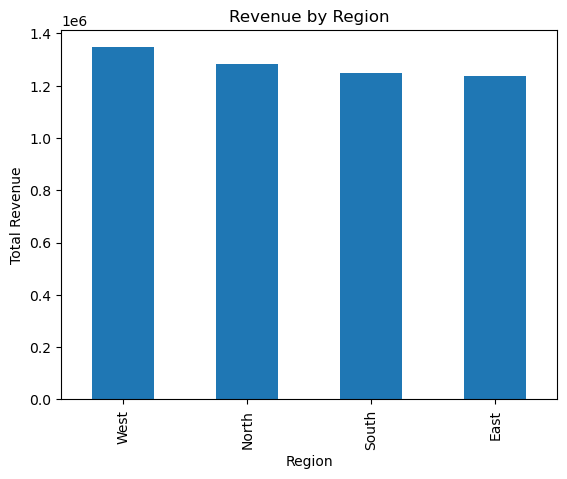

In [45]:
region_sales.plot.bar()
plt.title('Revenue by Region')
plt.xlabel('Region')
plt.ylabel('Total Revenue')
plt.show()

In [48]:
payment_sales=df.groupby('payment_method')['revenue'].sum()
payment_sales=payment_sales.sort_values(ascending=False)
payment_sales

payment_method
Card      2366248.20
COD       1788408.44
Wallet     955119.10
Name: revenue, dtype: float64

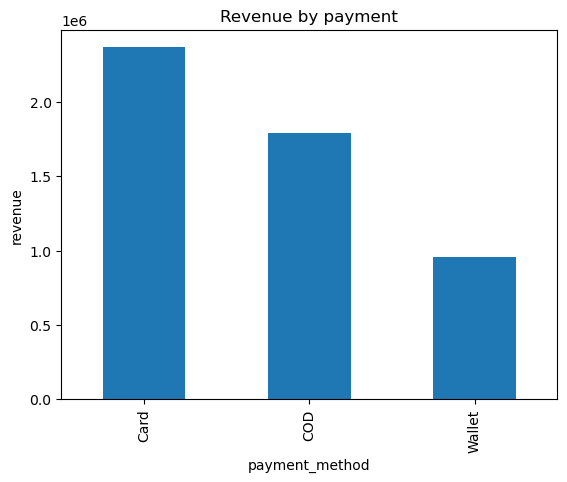

In [49]:
payment_sales.plot.bar()
plt.title('Revenue by payment')
plt.xlabel('payment_method')
plt.ylabel('revenue')
plt.show()

In [51]:
df['month']=df['order_date'].dt.month
df['month']

0       1
1       1
2       1
3       1
4       1
       ..
4995    9
4996    9
4997    9
4998    9
4999    9
Name: month, Length: 5000, dtype: int32

In [52]:
monthly_sales=df.groupby('month')['revenue'].sum()
monthly_sales

month
1     426374.92
2     413890.24
3     425050.52
4     398715.16
5     479772.55
6     442941.58
7     440570.72
8     460874.78
9     402368.11
10    407873.12
11    410657.88
12    400686.16
Name: revenue, dtype: float64

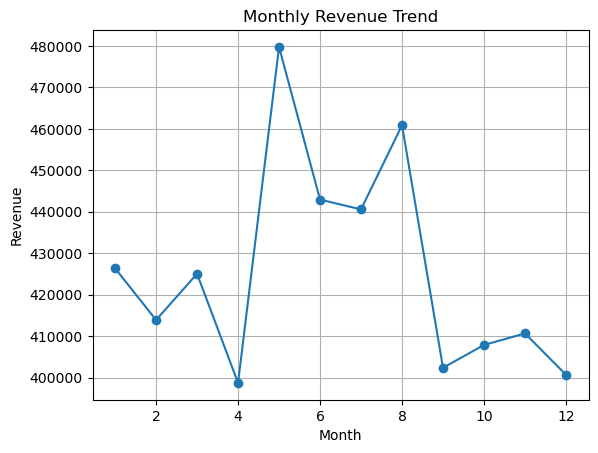

In [56]:
plt.plot(monthly_sales.index, monthly_sales.values, marker='o')
plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.grid()
plt.show()

In [59]:
customer_sales = df.groupby('customer_id')['revenue'].sum()
customer_sales=customer_sales.sort_values(ascending=False)
top_10_cust=customer_sales.head(10)
top_10_cust

customer_id
1663    17680.69
1955    16265.15
1675    15036.46
1276    15023.71
1647    14894.97
1804    14330.98
1193    14151.65
1836    14110.78
1957    13956.95
1735    13146.25
Name: revenue, dtype: float64

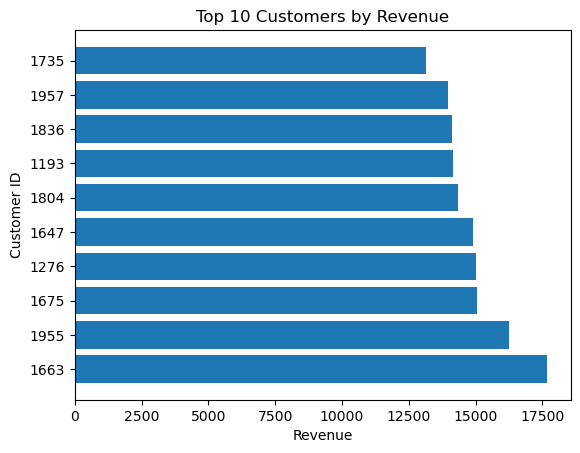

In [71]:
plt.barh(top_10_cust.index.astype(str), top_10_cust.values)
plt.title('Top 10 Customers by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Customer ID')
plt.show()

In [73]:
rating_by_category = df.groupby('product_category')['customer_rating'].mean()
rating_by_category

product_category
Beauty         3.008990
Clothing       3.005095
Electronics    2.951097
Home           2.940660
Name: customer_rating, dtype: float64

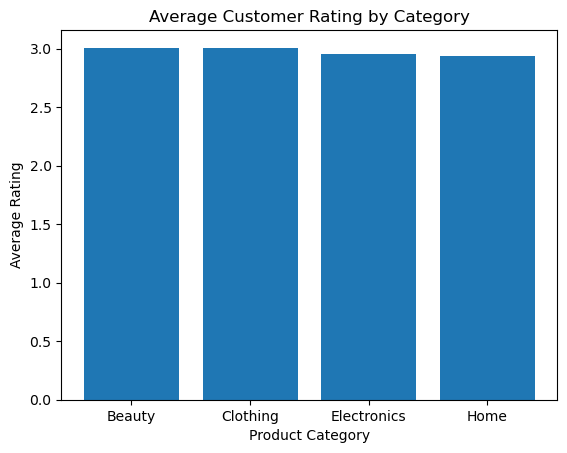

In [75]:
plt.bar(rating_by_category.index,rating_by_category.values)
plt.title('Average Customer Rating by Category')
plt.xlabel('Product Category')
plt.ylabel('Average Rating')
plt.show()

In [76]:
delivery_by_region = df.groupby('region')['delivery_days'].mean()
delivery_by_region

region
East     6.104319
North    6.118339
South    6.173013
West     6.082234
Name: delivery_days, dtype: float64

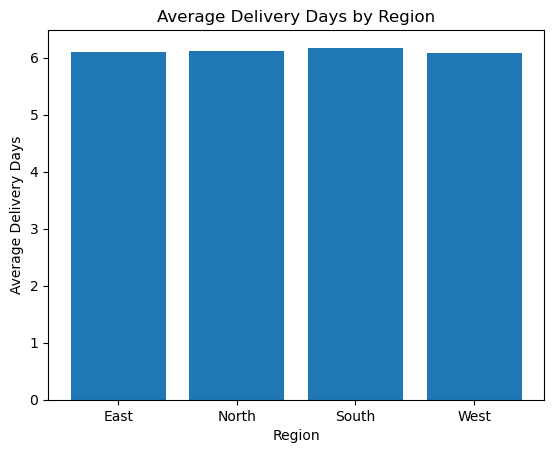

In [77]:
plt.bar(delivery_by_region.index,delivery_by_region.values)
plt.title('Average Delivery Days by Region')
plt.xlabel('Region')
plt.ylabel('Average Delivery Days')
plt.show()

In [78]:
total_revenue = df['revenue'].sum()
total_revenue

np.float64(5109775.74)

In [79]:
total_orders = df['order_id'].nunique()
total_orders

5000

In [80]:
total_customers = df['customer_id'].nunique()
total_customers

989

In [81]:
total_quantity = df['quantity'].sum()
total_quantity

np.int64(20224)

In [82]:
average_order_value = total_revenue / total_orders
average_order_value

np.float64(1021.955148)

In [83]:
df.to_csv('Ecommerce_Cleaned_Data.csv', index=False)